If import error shows up below, first run `pip install -e .` from the base directory of the project.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from halcyon.Models.CellBox import CellBox
from halcyon.Datasets.ExpressionDataWithConditions import ExpressionDataWithConditions
from halcyon.Trainer import Trainer
from halcyon.Models.NeuralODE import NeuralODE

import logging
from pathlib import Path

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

In [4]:
expressions =  ExpressionDataWithConditions.from_genenetweaver_ko_timeseries_output(
        Path('../tests/genenetweaver_outputs/test_scalefree_nonoise_knockout_timeseries.tsv')
    )
expressions.scale_time_series()

In [5]:
expressions.all_environments

('test', 'test2')

In [ ]:
# Neural ODE run this
model = NeuralODE(expressions.genes, expressions.all_environments)

2025-08-18 15:37:15,408 - INFO - Epoch 0, loss 0.007588797714561224
2025-08-18 15:37:17,226 - INFO - Epoch 1, loss 0.016758861020207405
2025-08-18 15:37:19,647 - INFO - Epoch 2, loss 0.010230152867734432
2025-08-18 15:37:21,829 - INFO - Epoch 3, loss 0.013442530296742916
2025-08-18 15:37:23,991 - INFO - Epoch 4, loss 0.010966291651129723
2025-08-18 15:37:25,832 - INFO - Epoch 5, loss 0.009123345836997032
2025-08-18 15:37:27,497 - INFO - Epoch 6, loss 0.00732275377959013
2025-08-18 15:37:29,194 - INFO - Epoch 7, loss 0.008950510993599892
2025-08-18 15:37:30,676 - INFO - Epoch 8, loss 0.009336410090327263
2025-08-18 15:37:32,615 - INFO - Epoch 9, loss 0.00797310471534729
2025-08-18 15:37:34,387 - INFO - Epoch 10, loss 0.007142253220081329
2025-08-18 15:37:36,083 - INFO - Epoch 11, loss 0.006837006658315659
2025-08-18 15:37:37,799 - INFO - Epoch 12, loss 0.006495553068816662
2025-08-18 15:37:39,476 - INFO - Epoch 13, loss 0.006605440750718117
2025-08-18 15:37:41,099 - INFO - Epoch 14, los

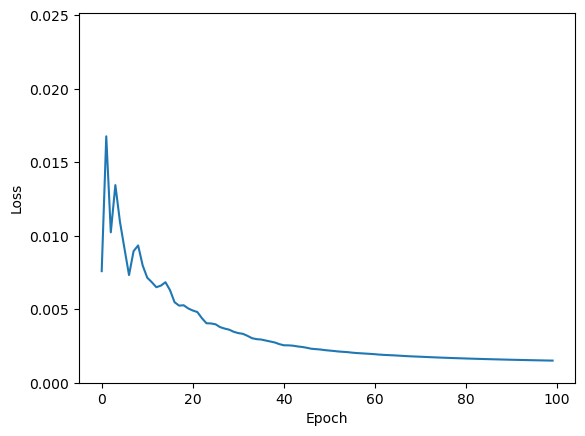

In [38]:
my_trainer = Trainer(model, expressions, batch_size=10, optimizer_kwargs={'lr': .1})
my_trainer.train(100)
my_trainer.plot_loss_history()

(<Figure size 1000x4000 with 20 Axes>,
 array([[<Axes: title={'center': 'Measured (Sample 0)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 0)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 1)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 1)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 2)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 2)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 3)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 3)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 4)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 4)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center'

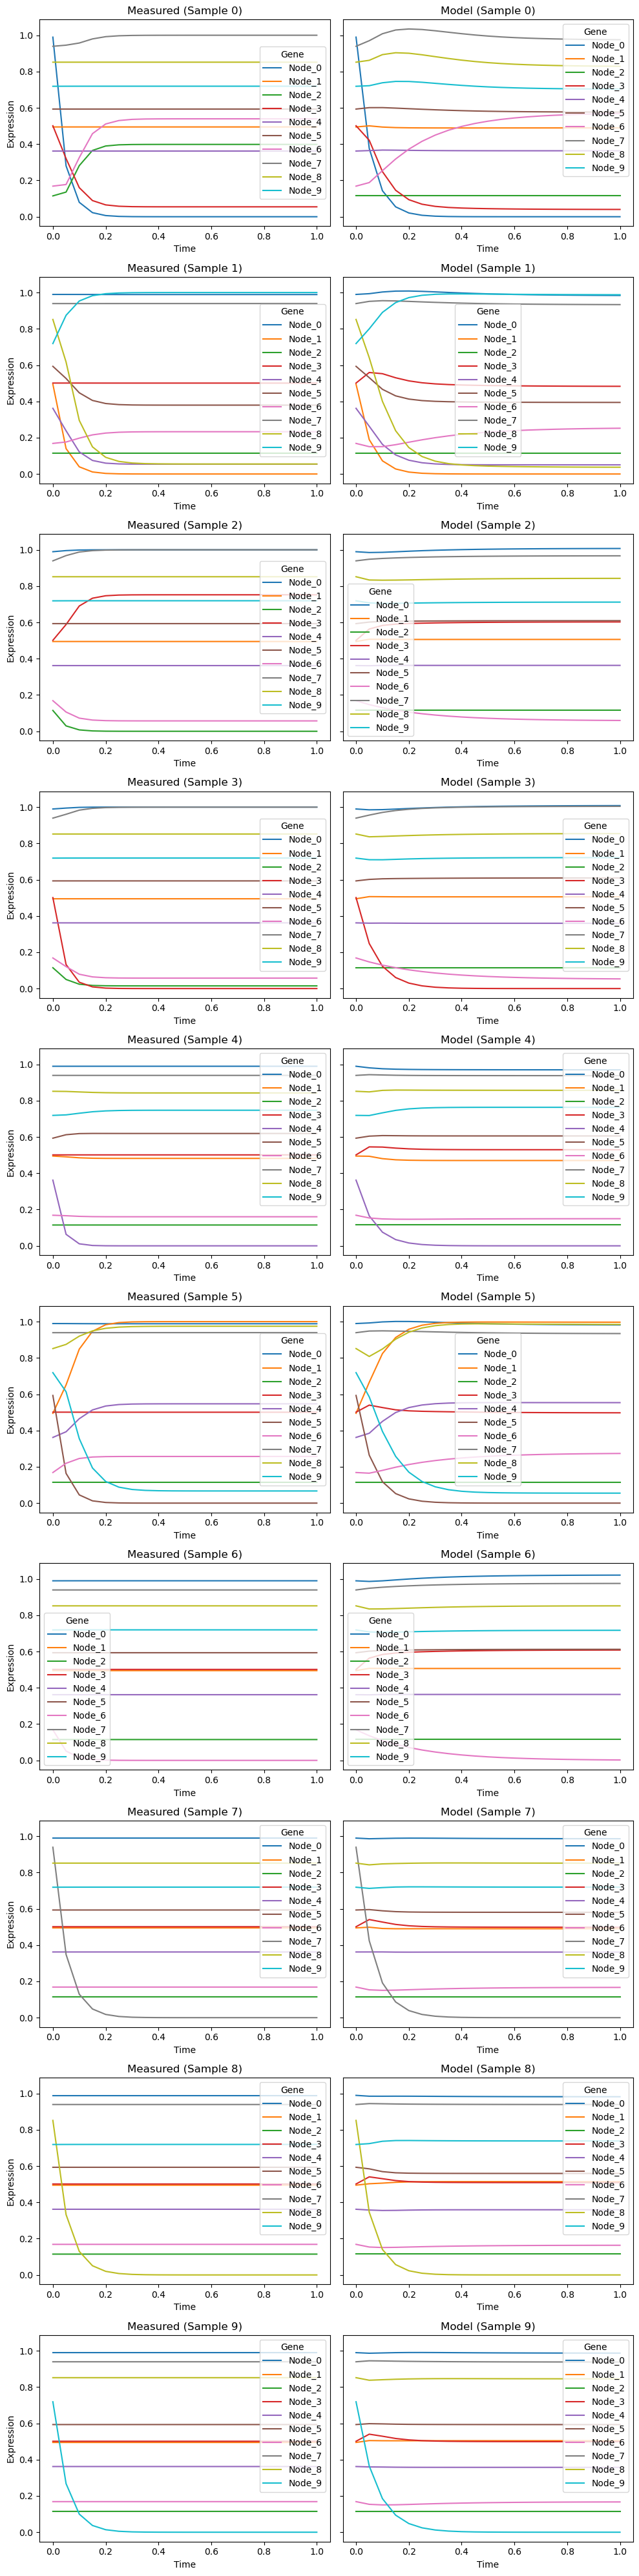

In [39]:
my_trainer.plot_fit_vs_real()

In [40]:
model.decay_params

Parameter containing:
tensor([2.3400, 2.4243, 0.6616, 2.1519, 2.6574, 2.4493, 2.6789, 2.0801, 2.2790,
        2.1494], requires_grad=True)

In [41]:
model.per_gene_multipliers

Parameter containing:
tensor([ 8.2623,  7.9225, -0.3324,  6.5374,  5.9120,  6.6017,  1.6121,  7.6442,
         7.9136,  6.3119], requires_grad=True)